# Backwards Muons Timing & Late Veto Cut Analysis

Investigation into the Late Veto Hit cut (`VetoCut.h`) and time-walk calibration effects on backwards-propagating muon events.

### Context & Datasets
- **Simulation**: Particle gun backwards muons ($13.6\text{ TeV}$, `sndLHC.PG_13-TGeant4_dig_b2nob1Muons.root`)
- **Data**: 2023 prefiltered run 6596 (`sndsw_raw-*.root`, $B_2$-only, stable beams, reconstructed negative track velocity)
- **Calibration**: SiPM time-walk fits and SciFi reference alignment (`catII_timing_calibration.json`)


---
## 1. Environment & Detector Constants


In [1]:
import os
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from scipy.optimize import curve_fit

try:
    import ddfUtils.mpl_styling as dms
    HAS_DMS = True
except ImportError:
    HAS_DMS = False

# Constants
TDC2NS = 1000.0 / 160.316
TAU_CUT = 0.3  # 300 ps threshold

DEFAULT_SIM_FILE = "/eos/user/i/idioniso/snd-numu-charm/data/pgun_backwards_muons/sndLHC.PG_13-TGeant4_dig_b2nob1Muons.root"
DEFAULT_DATA_DIR = "/eos/user/i/idioniso/snd-numu-charm/prefiltered/2023/b2nob1Muons/run006596"
DEFAULT_CALIB_FILE = "/eos/user/i/idioniso/Timing/timewalk/fits/catII_timing_calibration.json"
PLOTS_DIR = "/afs/cern.ch/work/i/idioniso/snd-veto-us/plots/backwards_muons"


---
## 2. Load Datasets & Caches

Loads pre-extracted bar-level dataframes for both simulation truth and real detector data.
Each record contains the earliest SciFi hit time $t_{\mathrm{SciFi}}^{\mathrm{earliest}}$ and the Veto bar-level time metrics:
- $t_{\mathrm{bar}} = \frac{1}{2}(t_{\mathrm{side\,0}} + t_{\mathrm{side\,1}})$ for horizontal bars (averaging both ends to cancel light propagation delay)
- $t_{\mathrm{bar}} = t_{\mathrm{side\,0}}$ for vertical bars


In [2]:
# Load precomputed parquet caches (or extract if not present)
sim_cache_path = os.path.join(PLOTS_DIR, "sim_cache_bar.parquet")
nu_cache_path = os.path.join(PLOTS_DIR, "nu_sim_cache_bar.parquet")
data_cache_path = os.path.join(PLOTS_DIR, "data_cache_bar_SF_5.parquet")

if os.path.exists(sim_cache_path):
    df_sim = pd.read_parquet(sim_cache_path)
    print(f"Loaded particle gun simulation events: {len(df_sim):,}")
else:
    print(f"Simulation cache not found at {sim_cache_path}.")

if os.path.exists(nu_cache_path):
    df_nu = pd.read_parquet(nu_cache_path)
    print(f"Loaded neutrino simulation events: {len(df_nu):,}")
else:
    df_nu = None
    print(f"Neutrino cache not found at {nu_cache_path}.")

if os.path.exists(data_cache_path):
    df_data = pd.read_parquet(data_cache_path)
    print(f"Loaded data events: {len(df_data):,}")
else:
    print(f"Data cache not found at {data_cache_path}.")


Loaded particle gun simulation events: 2,056
Loaded neutrino simulation events: 325
Loaded data events: 58,342


---
## 3. Analysis Functions & Fitting Utilities


In [3]:
def gaus_func(x, a, mu, sigma):
    return a * np.exp(-0.5 * ((x - mu) / max(1e-6, sigma)) ** 2)

def fit_gaussian_core(data, bins=80, range_x=(-10.0, 10.0), n_sigma=1.8):
    """Fits Gaussian core to histogram peak within n_sigma around median."""
    vals = data[(data >= range_x[0]) & (data <= range_x[1])].dropna().values
    if len(vals) < 30:
        return None
    counts, edges = np.histogram(vals, bins=bins, range=range_x)
    mids = 0.5 * (edges[:-1] + edges[1:])
    p_idx = np.argmax(counts)
    init_mu = mids[p_idx]
    init_amp = counts[p_idx]
    init_sig = np.std(vals)
    mask = (mids >= init_mu - n_sigma * init_sig) & (mids <= init_mu + n_sigma * init_sig)
    if np.sum(mask) < 4:
        return None
    try:
        popt, _ = curve_fit(
            gaus_func, mids[mask], counts[mask],
            p0=[init_amp, init_mu, init_sig],
            bounds=([0, init_mu - 3.0, 0.05], [init_amp * 2.5, init_mu + 3.0, 5.0]),
            maxfev=3000
        )
        return {"amp": popt[0], "mu": popt[1], "sigma": abs(popt[2])}
    except Exception:
        return None


---
## 4. Late Veto Cut 4-Panel Investigation

Displays the master 4-panel diagnostic figure:
1. **Simulation (MC Truth)**: Distribution of worst-case ($\Delta t_{\mathrm{min}}$) and latest ($\Delta t_{\mathrm{max}}$) veto bar arrivals.
2. **Real Data (Unsynchronized DAQ Clocks)**: Raw DAQ vs. Calibrated (TW + Alignment) $\Delta t$, demonstrating the $\sim 6.5\text{ ns}$ global hardware DAQ delay.
3. **Threshold Scan $\epsilon(\tau)$**: Late veto survival efficiency scan showing $>99.6\%$ backwards muon survival at $\tau = 300\text{ ps}$.
4. **Synchronized Overlay**: Direct physical comparison between simulation truth and synchronized real detector data.


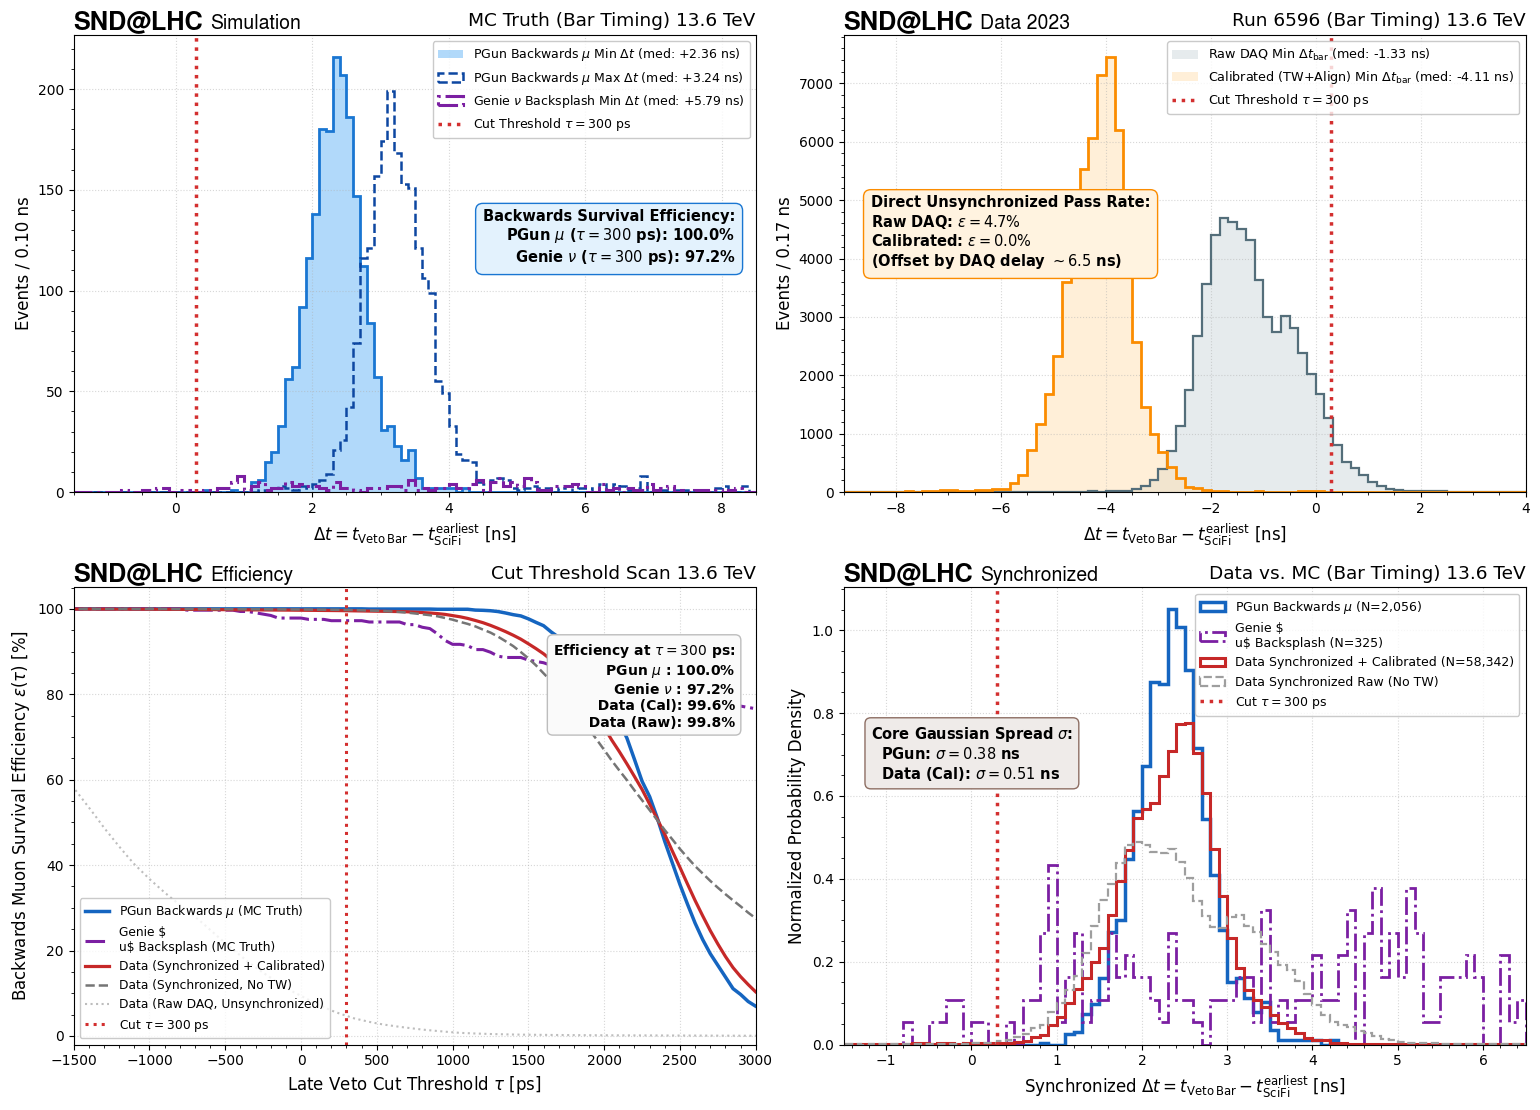

In [4]:
# --- Generate the 4-Panel Master Figure ---
fig, axes = plt.subplots(2, 2, figsize=(15.5, 11.2))
(ax1, ax2), (ax3, ax4) = axes

tau_cut = TAU_CUT

# --- Panel 1: Simulation (MC Truth) ---
bins_sim = np.linspace(-2.0, 9.0, 111)
med_sim_min = np.median(df_sim["dt_min"])
med_sim_max = np.median(df_sim["dt_max"])

ax1.hist(df_sim["dt_min"], bins=bins_sim, histtype="stepfilled", color="#64B5F6", alpha=0.5,
         label=rf"PGun Backwards $\mu$ Min $\Delta t$ (med: {med_sim_min:+.2f} ns)")
ax1.hist(df_sim["dt_min"], bins=bins_sim, histtype="step", color="#1976D2", linewidth=2.0)
ax1.hist(df_sim["dt_max"], bins=bins_sim, histtype="step", color="#0D47A1", linewidth=1.8, linestyle="--",
         label=rf"PGun Backwards $\mu$ Max $\Delta t$ (med: {med_sim_max:+.2f} ns)")

if df_nu is not None and len(df_nu) > 0:
    med_nu_min = np.median(df_nu["dt_min"])
    ax1.hist(df_nu["dt_min"], bins=bins_sim, histtype="step", color="#7B1FA2", linewidth=2.2, linestyle="-.",
             label=rf"Genie $\nu$ Backsplash Min $\Delta t$ (med: {med_nu_min:+.2f} ns)")

ax1.axvline(tau_cut, color="#D32F2F", linestyle=":", linewidth=2.5,
            label=rf"Cut Threshold $\tau = {int(tau_cut*1000)}$ ps")

pass_sim_300 = np.mean(df_sim["dt_min"] >= tau_cut) * 100.0
pass_nu_300 = np.mean(df_nu["dt_min"] >= tau_cut) * 100.0 if df_nu is not None else None

tbox1 = (
    "Backwards Survival Efficiency:\n"
    rf"  PGun $\mu$ ($\tau={int(tau_cut*1000)}$ ps): {pass_sim_300:.1f}%"
)
if pass_nu_300 is not None:
    tbox1 += f"\n  Genie $\\nu$ ($\\tau={int(tau_cut*1000)}$ ps): {pass_nu_300:.1f}%"

ax1.text(0.97, 0.62, tbox1,
         transform=ax1.transAxes, ha="right", va="top",
         fontsize=10.5, fontweight="bold",
         bbox=dict(boxstyle="round,pad=0.5", facecolor="#E3F2FD", edgecolor="#1976D2"))

ax1.set_xlabel(r"$\Delta t = t_{\mathrm{Veto\,Bar}} - t_{\mathrm{SciFi}}^{\mathrm{earliest}}$ [ns]", fontsize=12)
ax1.set_ylabel(f"Events / {bins_sim[1]-bins_sim[0]:.2f} ns", fontsize=12)
ax1.set_xlim(-1.5, 8.5)
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.legend(frameon=True, facecolor="white", edgecolor="#BDBDBD", loc="upper right", fontsize=9.0)
if HAS_DMS:
    dms.add_label(ax=ax1, mainText="SND@LHC", extraText="Simulation", suppText="MC Truth (Bar Timing)")
else:
    ax1.set_title("(a) Simulation (MC Truth): Late Veto Bars", fontsize=13, loc="left")

# --- Panel 2: Real Data (Raw DAQ vs. Calibrated) ---
bins_data = np.linspace(-9.0, 5.0, 85)
med_data_raw = np.median(df_data["raw_min_dt"])
med_data_cal = np.median(df_data["cal_min_dt"])

ax2.hist(df_data["raw_min_dt"], bins=bins_data, histtype="stepfilled", color="#CFD8DC", alpha=0.5,
         label=rf"Raw DAQ Min $\Delta t_{{\mathrm{{bar}}}}$ (med: {med_data_raw:+.2f} ns)")
ax2.hist(df_data["raw_min_dt"], bins=bins_data, histtype="step", color="#546E7A", linewidth=1.6)

ax2.hist(df_data["cal_min_dt"], bins=bins_data, histtype="stepfilled", color="#FFE0B2", alpha=0.5,
         label=rf"Calibrated (TW+Align) Min $\Delta t_{{\mathrm{{bar}}}}$ (med: {med_data_cal:+.2f} ns)")
ax2.hist(df_data["cal_min_dt"], bins=bins_data, histtype="step", color="#FB8C00", linewidth=2.0)

ax2.axvline(tau_cut, color="#D32F2F", linestyle=":", linewidth=2.5,
            label=rf"Cut Threshold $\tau = {int(tau_cut*1000)}$ ps")

raw_pass = np.mean(df_data["raw_min_dt"] >= tau_cut) * 100.0
cal_pass = np.mean(df_data["cal_min_dt"] >= tau_cut) * 100.0

tbox2 = (
    "Direct Unsynchronized Pass Rate:\n"
    f"Raw DAQ: $\\epsilon = {raw_pass:.1f}\\%$\n"
    f"Calibrated: $\\epsilon = {cal_pass:.1f}\\%$\n"
    f"(Offset by DAQ delay $\\sim 6.5$ ns)"
)
ax2.text(0.04, 0.65, tbox2,
         transform=ax2.transAxes, ha="left", va="top",
         fontsize=10.5, fontweight="bold",
         bbox=dict(boxstyle="round,pad=0.5", facecolor="#FFF3E0", edgecolor="#FB8C00"))

ax2.set_xlabel(r"$\Delta t = t_{\mathrm{Veto\,Bar}} - t_{\mathrm{SciFi}}^{\mathrm{earliest}}$ [ns]", fontsize=12)
ax2.set_ylabel(f"Events / {bins_data[1]-bins_data[0]:.2f} ns", fontsize=12)
ax2.set_xlim(-9.0, 4.0)
ax2.xaxis.set_minor_locator(AutoMinorLocator())
ax2.yaxis.set_minor_locator(AutoMinorLocator())
ax2.grid(True, linestyle=":", alpha=0.5)
ax2.legend(frameon=True, facecolor="white", edgecolor="#BDBDBD", loc="upper right", fontsize=9.2)
if HAS_DMS:
    dms.add_label(ax=ax2, mainText="SND@LHC", extraText="Data 2023", suppText="Run 6596 (Bar Timing)")
else:
    ax2.set_title("(b) Real Detector Data: Unsynchronized DAQ Clocks", fontsize=13, loc="left")

# --- Panel 3: Survival Efficiency vs. Threshold Tau ---
taus = np.linspace(-3.0, 4.0, 141)
eff_sim = [np.mean(df_sim["dt_min"] >= t) * 100.0 for t in taus]
eff_nu = [np.mean(df_nu["dt_min"] >= t) * 100.0 for t in taus] if df_nu is not None else None
eff_data_raw = [np.mean(df_data["raw_min_dt"] >= t) * 100.0 for t in taus]

offset_raw = np.median(df_sim["dt_min"]) - np.median(df_data["raw_min_dt"])
offset_cal = np.median(df_sim["dt_min"]) - np.median(df_data["cal_min_dt"])

aligned_data_raw = df_data["raw_min_dt"] + offset_raw
aligned_data_cal = df_data["cal_min_dt"] + offset_cal

eff_data_synch_raw = [np.mean(aligned_data_raw >= t) * 100.0 for t in taus]
eff_data_synch_cal = [np.mean(aligned_data_cal >= t) * 100.0 for t in taus]

ax3.plot(taus * 1000.0, eff_sim, color="#1565C0", linewidth=2.5, label="PGun Backwards $\mu$ (MC Truth)")
if eff_nu is not None:
    ax3.plot(taus * 1000.0, eff_nu, color="#7B1FA2", linewidth=2.2, linestyle="-.", label="Genie $\nu$ Backsplash (MC Truth)")
ax3.plot(taus * 1000.0, eff_data_synch_cal, color="#C62828", linewidth=2.3, label="Data (Synchronized + Calibrated)")
ax3.plot(taus * 1000.0, eff_data_synch_raw, color="#757575", linewidth=1.8, linestyle="--", label="Data (Synchronized, No TW)")
ax3.plot(taus * 1000.0, eff_data_raw, color="#BDBDBD", linewidth=1.5, linestyle=":", label="Data (Raw DAQ, Unsynchronized)")

ax3.axvline(tau_cut * 1000.0, color="#D32F2F", linestyle=":", linewidth=2.2, label=rf"Cut $\tau = {int(tau_cut*1000)}$ ps")
ax3.set_xlabel(r"Late Veto Cut Threshold $\tau$ [ps]", fontsize=12)
ax3.set_ylabel(r"Backwards Muon Survival Efficiency $\epsilon(\tau)$ [%]", fontsize=12)
ax3.set_xlim(-1500, 3000)
ax3.set_ylim(-2.0, 105.0)
ax3.xaxis.set_minor_locator(AutoMinorLocator())
ax3.yaxis.set_minor_locator(AutoMinorLocator())
ax3.grid(True, linestyle=":", alpha=0.5)
ax3.legend(frameon=True, facecolor="white", edgecolor="#BDBDBD", loc="lower left", fontsize=8.8)

eff_synch_cal_300 = np.mean(aligned_data_cal >= tau_cut) * 100.0
eff_synch_raw_300 = np.mean(aligned_data_raw >= tau_cut) * 100.0

tbox3 = (
    rf"Efficiency at $\tau = 300$ ps:" + "\n"
    rf"  PGun $\mu$ : {pass_sim_300:.1f}%" + "\n"
)
if pass_nu_300 is not None:
    tbox3 += rf"  Genie $\nu$ : {pass_nu_300:.1f}%" + "\n"
tbox3 += (
    rf"  Data (Cal): {eff_synch_cal_300:.1f}%" + "\n"
    rf"  Data (Raw): {eff_synch_raw_300:.1f}%"
)

ax3.text(0.97, 0.88, tbox3,
         transform=ax3.transAxes, ha="right", va="top",
         fontsize=10.0, fontweight="bold",
         bbox=dict(boxstyle="round,pad=0.4", facecolor="#FAFAFA", edgecolor="#BDBDBD"))

if HAS_DMS:
    dms.add_label(ax=ax3, mainText="SND@LHC", extraText="Efficiency", suppText="Cut Threshold Scan")
else:
    ax3.set_title("(c) Backwards Muon Survival Efficiency Scan", fontsize=13, loc="left")

# --- Panel 4: Synchronized Comparison (Data vs Simulation) ---
bins_comp = np.linspace(-2.0, 7.0, 91)
ax4.hist(df_sim["dt_min"], bins=bins_comp, density=True, histtype="step", color="#1565C0", linewidth=2.5,
         label=f"PGun Backwards $\mu$ (N={len(df_sim):,})")
if df_nu is not None and len(df_nu) > 0:
    ax4.hist(df_nu["dt_min"], bins=bins_comp, density=True, histtype="step", color="#7B1FA2", linewidth=2.0, linestyle="-.",
             label=f"Genie $\nu$ Backsplash (N={len(df_nu):,})")
ax4.hist(aligned_data_cal, bins=bins_comp, density=True, histtype="step", color="#C62828", linewidth=2.2,
         label=f"Data Synchronized + Calibrated (N={len(df_data):,})")
ax4.hist(aligned_data_raw, bins=bins_comp, density=True, histtype="step", color="#9E9E9E", linewidth=1.6, linestyle="--",
         label="Data Synchronized Raw (No TW)")

ax4.axvline(tau_cut, color="#D32F2F", linestyle=":", linewidth=2.5,
            label=rf"Cut $\tau = {int(tau_cut*1000)}$ ps")
ax4.set_xlabel(r"Synchronized $\Delta t = t_{\mathrm{Veto\,Bar}} - t_{\mathrm{SciFi}}^{\mathrm{earliest}}$ [ns]", fontsize=12)
ax4.set_ylabel("Normalized Probability Density", fontsize=12)
ax4.set_xlim(-1.5, 6.5)
ax4.xaxis.set_minor_locator(AutoMinorLocator())
ax4.yaxis.set_minor_locator(AutoMinorLocator())
ax4.grid(True, linestyle=":", alpha=0.5)
ax4.legend(frameon=True, facecolor="white", edgecolor="#BDBDBD", loc="upper right", fontsize=9.0)

fit_sim = fit_gaussian_core(df_sim["dt_min"], bins=80, range_x=(-2.0, 6.0))
fit_dat = fit_gaussian_core(aligned_data_cal, bins=80, range_x=(-2.0, 6.0))
if fit_sim and fit_dat:
    tbox4 = (
        "Core Gaussian Spread $\\sigma$:\n"
        f"  PGun: $\\sigma = {fit_sim['sigma']:.2f}$ ns\n"
        f"  Data (Cal): $\\sigma = {fit_dat['sigma']:.2f}$ ns"
    )
    ax4.text(0.04, 0.70, tbox4,
             transform=ax4.transAxes, ha="left", va="top",
             fontsize=10.5, fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.4", facecolor="#EFEBE9", edgecolor="#8D6E63"))

if HAS_DMS:
    dms.add_label(ax=ax4, mainText="SND@LHC", extraText="Synchronized", suppText="Data vs. MC (Bar Timing)")
else:
    ax4.set_title("(d) Synchronized Physical Time-of-Flight Overlay", fontsize=13, loc="left")

fig.tight_layout()
plt.show()



---
## 5. Quantitative Summary Table


In [5]:
fit_raw_synch = fit_gaussian_core(aligned_data_raw, bins=80, range_x=(-2.0, 6.0))

summary_data = {
    "Configuration": [
        "PGun Backwards mu (MC Truth)",
        "Genie nu Backsplash (MC Truth)",
        "Data Raw DAQ (Unsynchronized)",
        "Data Synchronized (No TW)",
        "Data Synchronized + Calibrated"
    ],
    "Median dt [ns]": [
        f"{np.median(df_sim['dt_min']):+.2f}",
        f"{np.median(df_nu['dt_min']):+.2f}" if df_nu is not None else "—",
        f"{np.median(df_data['raw_min_dt']):+.2f}",
        f"{np.median(aligned_data_raw):+.2f}",
        f"{np.median(aligned_data_cal):+.2f}"
    ],
    "Core Gaussian sigma [ns]": [
        f"{fit_sim['sigma']:.3f}" if fit_sim else "—",
        "Broad (shower backsplash)",
        "—",
        f"{fit_raw_synch['sigma']:.3f}" if fit_raw_synch else "—",
        f"{fit_dat['sigma']:.3f}" if fit_dat else "—"
    ],
    "Survival Efficiency at tau=300 ps [%]": [
        f"{pass_sim_300:.1f}%",
        f"{pass_nu_300:.1f}%" if pass_nu_300 is not None else "—",
        f"{raw_pass:.1f}%",
        f"{eff_synch_raw_300:.1f}%",
        f"{eff_synch_cal_300:.1f}%"
    ]
}

df_summary = pd.DataFrame(summary_data)
display(df_summary)



,Configuration,Median dt [ns],Core Gaussian sigma [ns],Survival Efficiency at tau=300 ps [%]
0,PGun Backwards mu (MC Truth),+2.36,0.381,100.0%
1,Genie nu Backsplash (MC Truth),+5.79,Broad (shower backsplash),97.2%
2,Data Raw DAQ (Unsynchronized),-1.33,—,4.7%
3,Data Synchronized (No TW),+2.36,0.792,99.8%
4,Data Synchronized + Calibrated,+2.36,0.513,99.6%


---
## 6. Pre-rendered High-Resolution Figure


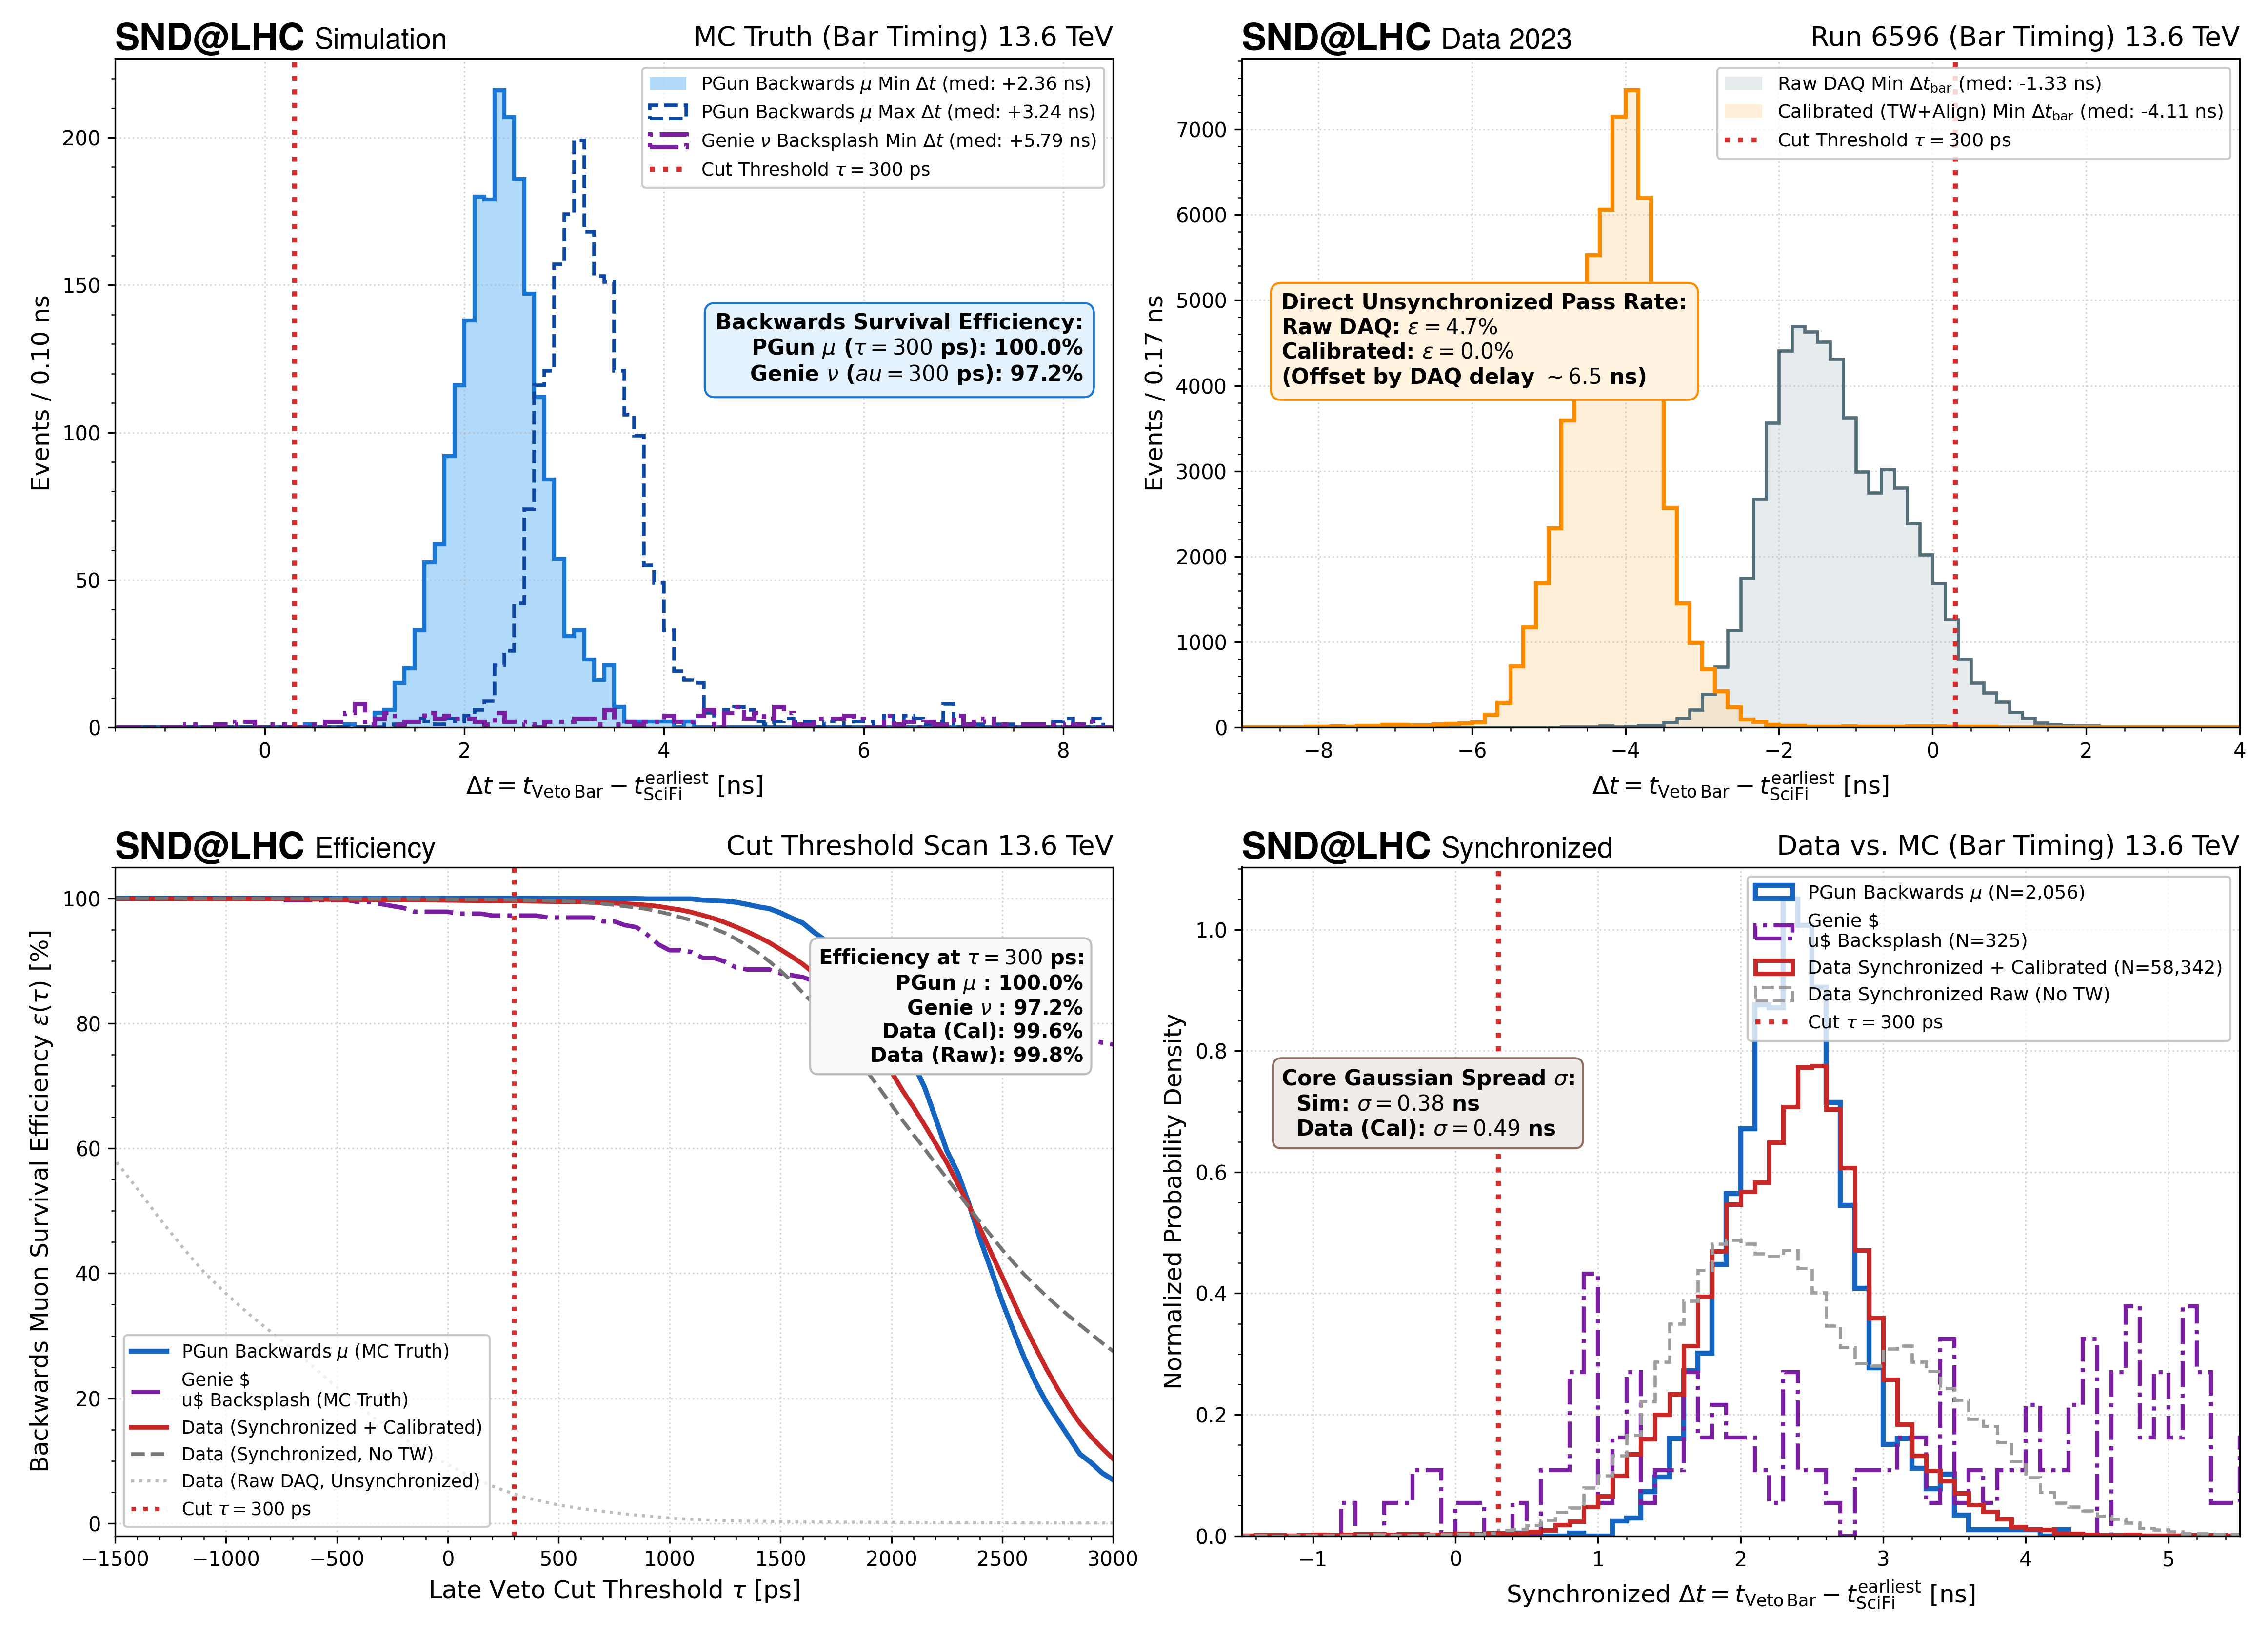

In [6]:
from IPython.display import Image, display

saved_fig_path = os.path.join(PLOTS_DIR, "backwards_muons_late_veto_analysis.png")
if os.path.exists(saved_fig_path):
    display(Image(filename=saved_fig_path))
else:
    print("Pre-rendered figure not found at:", saved_fig_path)
